## Lab 7: $k$-medoids and $c$-means
You can use external libraries for linear algebra operations (e.g. `numpy`) but you are expected to write your own algorithms. In this notebook `sklearn`, `kmedoids` and `scikit-fuzzy` are used only to **check** our implementations, never to produce the results.

In [23]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Exercise 1
Use the `s3.txt` dataset from the previous lab. As in the previous lab, the first thing to do is to look at the data. Here we also standardize the two coordinates (zero mean, unit variance), so that the values of the losses are easier to read.

(5000, 2)


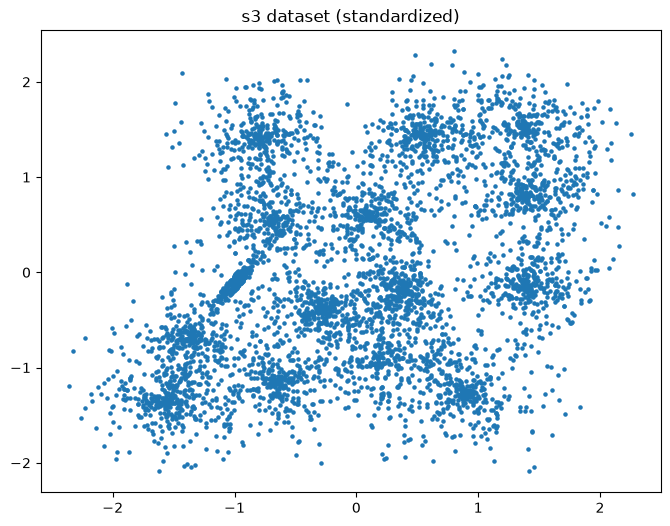

In [24]:
s3 = np.genfromtxt("../Datasets/s3.txt")
s3 = (s3 - s3.mean(axis=0)) / s3.std(axis=0)
print(s3.shape)

plt.figure(figsize=(8, 6))
plt.scatter(s3[:, 0], s3[:, 1], s=5)
plt.title("s3 dataset (standardized)")
plt.show()

1. Run **your** $k$-means code 20 times with $k=15$. Save the minimum, the maximum and the average values of the loss.

We reuse the $k$-means of the previous lab, with a small modification: the function takes an `init` argument that selects how the initial centroids are chosen (`"random"` for now). The loss is the sum of the **squared** distances $L=\sum_i\|x_i-\mu_{c(i)}\|^2$.

In [25]:
def sq_dist(X, C):
    """(n, k) matrix of squared euclidean distances between the rows of X and the rows of C (no python loops)."""
    D = (X ** 2).sum(axis=1, keepdims=True) - 2 * X @ C.T + (C ** 2).sum(axis=1)
    return np.maximum(D, 0)                       # clip tiny negative values due to rounding


def init_random(X, k, rng):
    """k distinct data points chosen uniformly at random."""
    return X[rng.choice(len(X), size=k, replace=False)].copy()


def kmeans(X, k, init="random", max_iter=300, rng=None):
    """Lloyd's k-means. Returns labels, centroids, final loss and the loss history."""
    rng = np.random.default_rng() if rng is None else rng
    n = X.shape[0]
    centroids = init_random(X, k, rng) if init == "random" else init_kmeanspp(X, k, rng)

    labels, history = None, []
    for it in range(max_iter):
        D = sq_dist(X, centroids)
        new_labels = D.argmin(axis=1)                                  # assignment step
        history.append(D[np.arange(n), new_labels].sum())
        if labels is not None and np.array_equal(new_labels, labels):  # converged
            break
        labels = new_labels
        for j in range(k):                                             # update step
            members = X[labels == j]
            if len(members) > 0:                                       # keep old centroid if the cluster is empty
                centroids[j] = members.mean(axis=0)
    loss = ((X - centroids[labels]) ** 2).sum()
    return labels, centroids, loss, history

In [26]:
def init_kmeanspp(X, k, rng):
    raise NotImplementedError("see point 2")   # defined later in the notebook

In [27]:
k = 15
n_runs = 20

losses_rand = np.array([kmeans(s3, k, init="random", rng=np.random.default_rng(i))[2] for i in range(n_runs)])
print(np.round(losses_rand, 2))
print(f"k-means (random init):  min = {losses_rand.min():.2f}   max = {losses_rand.max():.2f}   mean = {losses_rand.mean():.2f}")

[534.55 530.55 485.7  487.47 545.06 482.59 478.34 477.58 432.   534.74
 431.99 491.41 490.55 490.46 431.99 432.03 480.8  483.87 482.78 481.1 ]
k-means (random init):  min = 431.99   max = 545.06   mean = 484.28


2. Modify your code such that it uses the $k$-means++ initialization. Perform the same experiment of point 1 and compare the obtained values.

**$k$-means++** (Arthur & Vassilvitskii, 2007) spreads the initial centroids: the first one is a uniformly random data point; each following one is drawn among the data points with probability proportional to $D(x)^2$, the squared distance from $x$ to the closest centroid already chosen. Points far from every current centroid are therefore much more likely to be selected.

In [28]:
def init_kmeanspp(X, k, rng):
    """k-means++ seeding."""
    n = X.shape[0]
    centroids = [X[rng.integers(n)]]
    d2 = sq_dist(X, np.array(centroids)).min(axis=1)          # squared distance to the closest chosen centroid
    for _ in range(1, k):
        probs = d2 / d2.sum()
        centroids.append(X[rng.choice(n, p=probs)])
        d2 = np.minimum(d2, sq_dist(X, centroids[-1][None, :])[:, 0])   # only the new centroid can reduce d2
    return np.array(centroids)

In [29]:
losses_pp = np.array([kmeans(s3, k, init="kmeans++", rng=np.random.default_rng(i))[2] for i in range(n_runs)])
print(np.round(losses_pp, 2))
print(f"k-means++ init:         min = {losses_pp.min():.2f}   max = {losses_pp.max():.2f}   mean = {losses_pp.mean():.2f}")
print("random init  ->", f"min = {losses_rand.min():.2f}   max = {losses_rand.max():.2f}   mean = {losses_rand.mean():.2f}")

[485.59 528.03 486.69 483.89 478.33 482.74 493.84 478.13 431.99 432.04
 540.34 432.04 480.28 475.82 432.05 431.99 482.79 543.12 432.   527.34]
k-means++ init:         min = 431.99   max = 543.12   mean = 477.95
random init  -> min = 431.99   max = 545.06   mean = 484.28


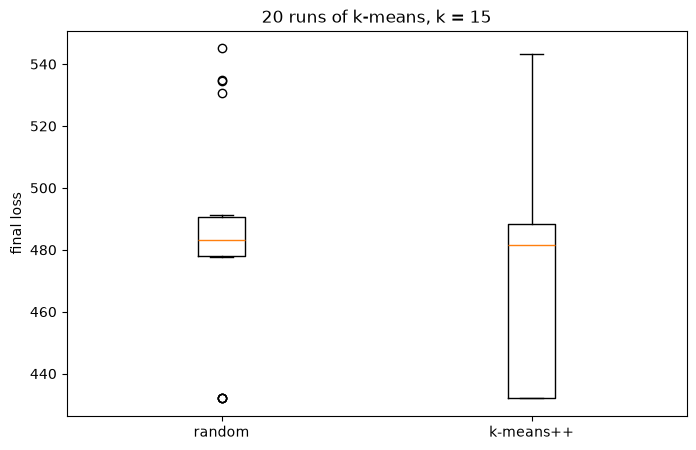

In [30]:
plt.figure(figsize=(8, 5))
plt.boxplot([losses_rand, losses_pp])
plt.xticks([1, 2], ["random", "k-means++"])
plt.ylabel("final loss")
plt.title(f"20 runs of k-means, k = {k}")
plt.show()

**Discussion.** In both cases the lowest loss is the same ($\approx 432$): this is (very likely) the global optimum for $k=15$, with one centroid per true cluster. The runs that end above it ($\approx 480$ or $\approx 530$-$545$) are local minima in which some true clusters get two centroids while others are merged. $k$-means++ lowers the mean loss a little and makes the very bad runs somewhat less frequent, but on $s3$ the gain is modest: the 15 clusters are roughly Gaussian blobs of similar size, so a uniform random choice is already reasonable. The advantage of $k$-means++ is larger with unbalanced or very numerous clusters, and it comes with a theoretical guarantee ($O(\log k)$-competitive in expectation). The price is the sequential computation of the distances during seeding. With 20 runs the numbers also depend on the random seeds, so do not over-interpret small differences.

3. Build a scree plot by plotting the best (i.e. the lowest) loss out of 20 runs for $k=2,\dots,20$ (with $k$-means++). What is the optimal value of $k$?

In [31]:
ks = range(2, 21)

def best_of_runs(fit, k, n_runs=20, seed=0):
    """Lowest loss out of n_runs runs of fit(k, rng) -> loss."""
    return min(fit(k, np.random.default_rng(seed + 1000 * k + i)) for i in range(n_runs))

fit_kmeans = lambda k, rng: kmeans(s3, k, init="kmeans++", rng=rng)[2]
loss_kmeans = [best_of_runs(fit_kmeans, k) for k in ks]

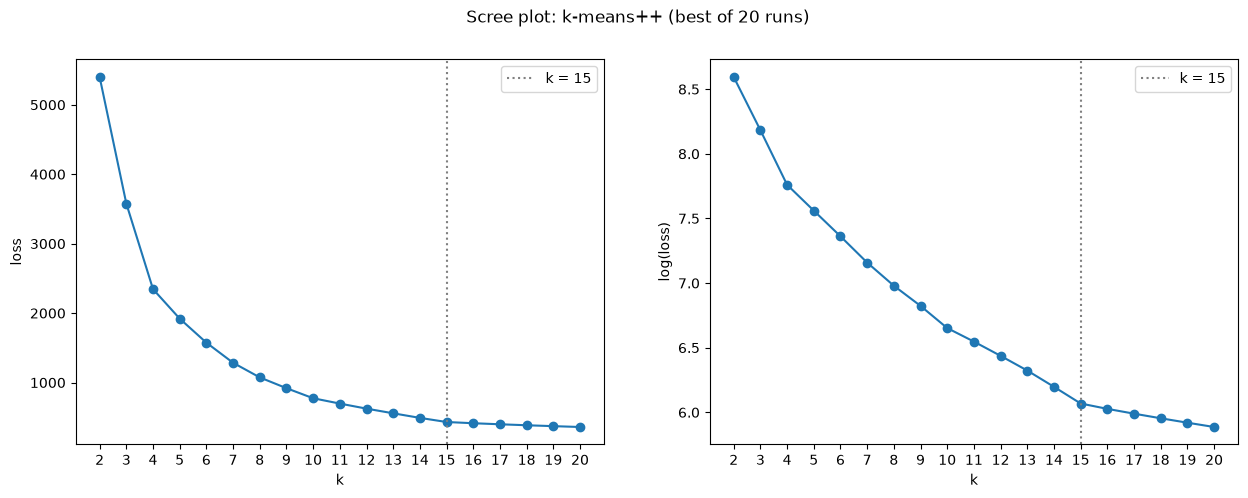

In [32]:
def scree(loss, title, axs=None):
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    for ax, f, lab in zip(axs, [lambda x: x, np.log], ["loss", "log(loss)"]):
        ax.plot(list(ks), f(np.array(loss)), "o-")
        ax.axvline(15, color="gray", ls=":", label="k = 15")
        ax.set_xticks(list(ks)); ax.set_xlabel("k"); ax.set_ylabel(lab); ax.legend()
    fig.suptitle(title)
    plt.show()

scree(loss_kmeans, "Scree plot: k-means++ (best of 20 runs)")

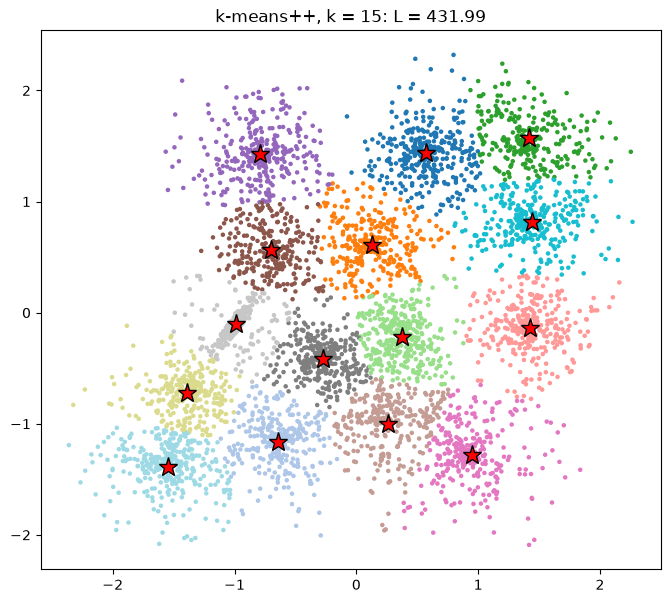

In [33]:
# Clustering with k = 15 (best of 20 runs)
runs = [kmeans(s3, 15, init="kmeans++", rng=np.random.default_rng(i)) for i in range(20)]
labels, cents, L, _ = min(runs, key=lambda r: r[2])
plt.figure(figsize=(8, 7))
plt.scatter(s3[:, 0], s3[:, 1], c=labels, cmap="tab20", s=5)
plt.plot(cents[:, 0], cents[:, 1], "r*", markersize=14, markeredgecolor="k")
plt.title(f"k-means++, k = 15: L = {L:.2f}")
plt.show()

**Discussion.** The loss decreases monotonically with $k$ (it must: more centroids can only help), so we cannot pick the minimum. We look for an *elbow*, a value after which adding a cluster brings only a small improvement. In the linear plot the curve is a smooth decay and the elbow is not sharp; the logarithmic plot makes it visible: the slope clearly changes around $k=14$-$15$, after which the curve is almost flat. This agrees with the 15 clusters that we can see in the scatter plot, so $k=15$ is the optimal value. Notice that the elbow criterion is subjective, and with overlapping clusters (as several of the ones in $s3$) it is only a hint.

4. Modify your code to perform $k$-medoids. Repeat the assignment of point 3 with the new implementation.

In $k$-medoids the centers are **actual data points** (the medoids) and the loss uses plain (not squared) distances, $L=\sum_i d(x_i,m_{c(i)})$, which makes it more robust to outliers. We use the simple alternating (Voronoi iteration) scheme: (1) assign every point to its closest medoid; (2) in every cluster, the new medoid is the member with the smallest sum of distances to the other members. Stop when the medoids do not change.

Since every step only needs the pairwise distances, we compute the full $n\times n$ matrix once.

In [34]:
def pairwise_dist(X):
    return np.sqrt(np.maximum(sq_dist(X, X), 0)).astype(np.float32)   # clip tiny negatives due to rounding

Dmat = pairwise_dist(s3)
print(Dmat.shape, f"{Dmat.nbytes / 1e6:.0f} MB")


def kmedoids(Dmat, k, max_iter=300, rng=None):
    """Alternating k-medoids on a precomputed distance matrix. Returns labels, medoid indices, loss."""
    rng = np.random.default_rng() if rng is None else rng
    n = Dmat.shape[0]
    medoids = rng.choice(n, size=k, replace=False)
    for it in range(max_iter):
        labels = Dmat[:, medoids].argmin(axis=1)                         # assignment step
        new_medoids = medoids.copy()
        for j in range(k):                                               # update step
            members = np.flatnonzero(labels == j)
            if len(members) > 0:
                within = Dmat[np.ix_(members, members)].sum(axis=1)      # sum of distances to the other members
                new_medoids[j] = members[within.argmin()]
        if np.array_equal(new_medoids, medoids):                         # converged
            break
        medoids = new_medoids
    labels = Dmat[:, medoids].argmin(axis=1)
    loss = Dmat[np.arange(len(labels)), medoids[labels]].sum()
    return labels, medoids, loss

(5000, 5000) 100 MB


In [35]:
# Sanity check against the kmedoids package (same algorithm: alternate, same initial medoids)
import kmedoids as kmd
rng = np.random.default_rng(0)
init_m = rng.choice(len(s3), size=15, replace=False)
ref = kmd.alternating(Dmat.astype(np.float64), init_m.copy(), max_iter=300)
ours = kmedoids(Dmat, 15, rng=np.random.default_rng(0))
print("kmedoids package loss:", ref.loss, " ours:", ours[2])

kmedoids package loss: 1375.6551859793847  ours: 1375.6553


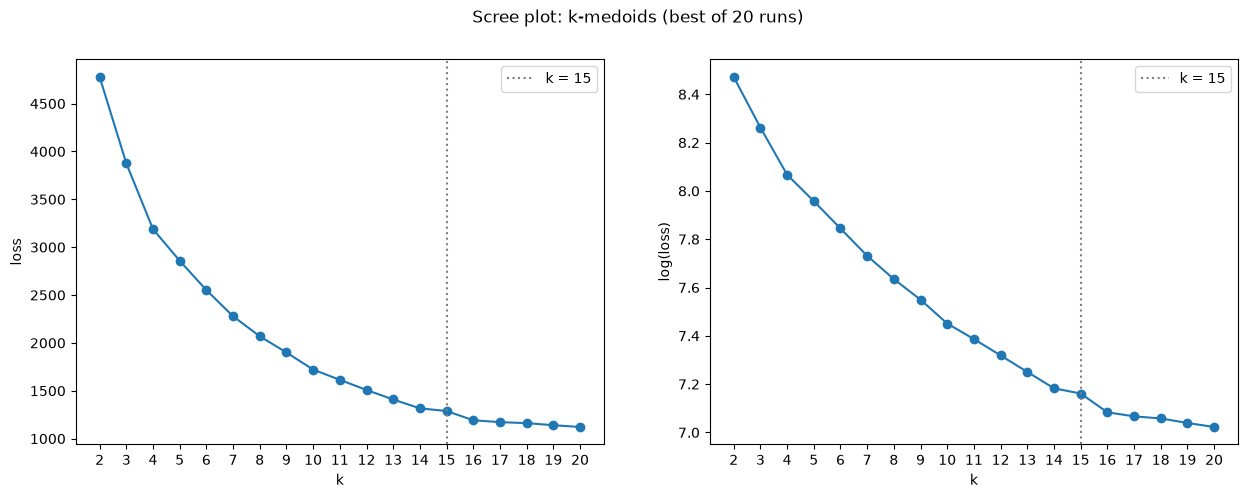

In [36]:
fit_kmedoids = lambda k, rng: kmedoids(Dmat, k, rng=rng)[2]
loss_kmedoids = [best_of_runs(fit_kmedoids, k) for k in ks]
scree(loss_kmedoids, "Scree plot: k-medoids (best of 20 runs)")

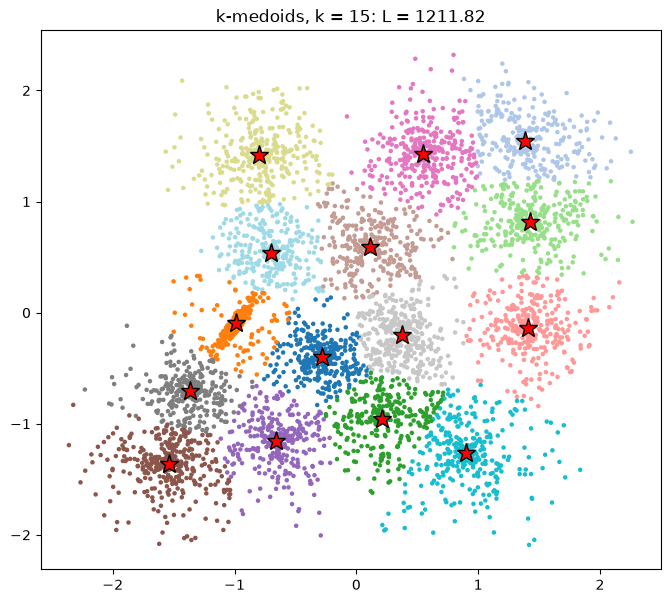

In [37]:
runs = [kmedoids(Dmat, 15, rng=np.random.default_rng(i)) for i in range(20)]
labels, med, L = min(runs, key=lambda r: r[2])
plt.figure(figsize=(8, 7))
plt.scatter(s3[:, 0], s3[:, 1], c=labels, cmap="tab20", s=5)
plt.plot(s3[med, 0], s3[med, 1], "r*", markersize=14, markeredgecolor="k")
plt.title(f"k-medoids, k = 15: L = {L:.2f}")
plt.show()

**Note on the magnitude of the losses.** The $k$-medoids loss sums plain distances while the $k$-means loss sums *squared* distances, so the two curves cannot be compared in absolute value (the same holds for the `inertia_` attribute of the library implementations: `KMeans` uses squared distances, `KMedoids` not). Only the **shape** of the curves is comparable.

**Discussion.** The scree plot of $k$-medoids has the same shape as the one of $k$-means (steep decrease and a bend close to $k=15$, then a flat tail), so the optimal $k$ is the same. The medoids are actual data points, so they sit slightly off the density peaks, and the clusters are very similar to the $k$-means ones. With the alternating algorithm the cost is much higher than for $k$-means: we need the $n\times n$ distance matrix (100 MB here) and each update is quadratic in the cluster size; the advantage is robustness to outliers and the fact that only a distance (or dissimilarity) matrix is needed, not the coordinates, so $k$-medoids works with any distance, e.g. for categorical data or strings.

5. Modify your code to perform $c$-means. Repeat the assignment of point 3 with the new implementation.

$c$-means (fuzzy $k$-means) gives every point a *membership* $u_{ij}\in[0,1]$ to each cluster $j$, with $\sum_j u_{ij}=1$. With fuzzifier $m>1$ it minimises
$$J_m=\sum_{i=1}^{n}\sum_{j=1}^{k}u_{ij}^{\,m}\,\|x_i-c_j\|^2 ,$$
alternating the two closed-form updates
$$c_j=\frac{\sum_i u_{ij}^m x_i}{\sum_i u_{ij}^m},\qquad u_{ij}=\left[\sum_{l=1}^{k}\left(\frac{\|x_i-c_j\|}{\|x_i-c_l\|}\right)^{\frac{2}{m-1}}\right]^{-1}$$
until the memberships change less than a tolerance. We use $m=2$. For $m\to1$ the method becomes $k$-means.

In [38]:
def cmeans(X, k, m=2.0, tol=1e-5, max_iter=1000, rng=None, U0=None):
    """Fuzzy c-means. Returns memberships U (n, k), centers (k, d), loss J_m and the number of iterations."""
    rng = np.random.default_rng() if rng is None else rng
    n = X.shape[0]
    if U0 is None:
        U0 = rng.random((n, k))
        U0 /= U0.sum(axis=1, keepdims=True)                   # random memberships, each row sums to 1
    U = U0
    for it in range(1, max_iter + 1):
        Um = U ** m
        centers = Um.T @ X / Um.sum(axis=0)[:, None]          # update centers
        d2 = np.maximum(sq_dist(X, centers), 1e-12)           # avoid division by zero
        inv = d2 ** (-1.0 / (m - 1))                          # (d^2)^(-1/(m-1)) = d^(-2/(m-1))
        U_new = inv / inv.sum(axis=1, keepdims=True)          # update memberships
        done = np.abs(U_new - U).max() < tol
        U = U_new
        if done:
            break
    Um = U ** m
    centers = Um.T @ X / Um.sum(axis=0)[:, None]
    loss = (Um * sq_dist(X, centers)).sum()
    return U, centers, loss, it

In [39]:
# Sanity check against scikit-fuzzy (same initial memberships)
from skfuzzy.cluster import cmeans as sk_cmeans
rng = np.random.default_rng(0)
U0 = rng.random((len(s3), 15)); U0 /= U0.sum(axis=1, keepdims=True)
U, cen, J, its = cmeans(s3, 15, U0=U0, tol=1e-5)
c_sk, u_sk, _, _, jm, p, _ = sk_cmeans(s3.T, c=15, m=2, error=1e-5, maxiter=1000, init=U0.T.copy())
print(f"scikit-fuzzy: J = {jm[-1]:.4f} ({p} it.)   ours: J = {J:.4f} ({its} it.)")

scikit-fuzzy: J = 217.6457 (102 it.)   ours: J = 217.6457 (89 it.)


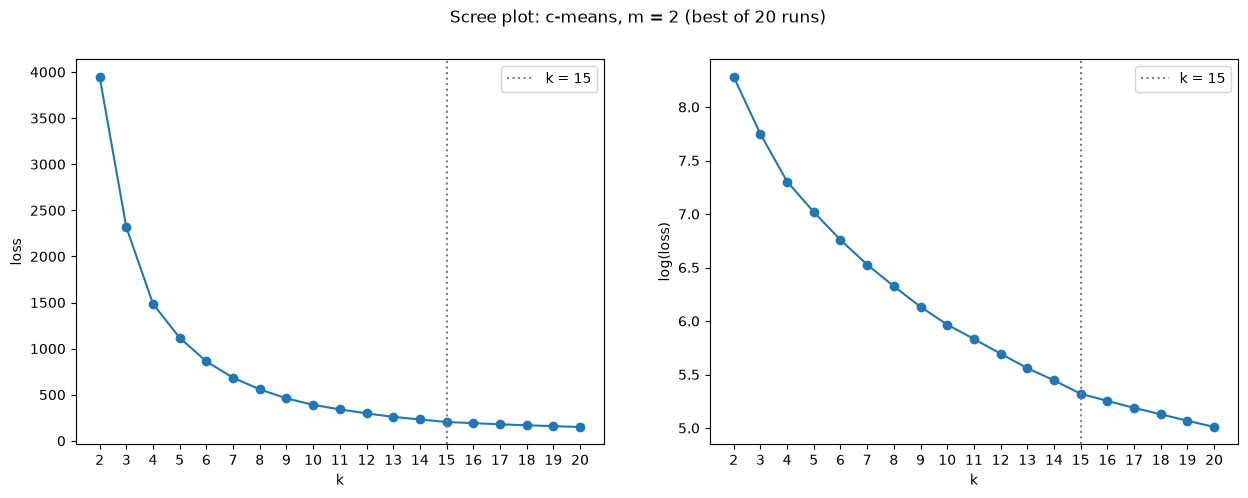

In [40]:
fit_cmeans = lambda k, rng: cmeans(s3, k, rng=rng)[2]
loss_cmeans = [best_of_runs(fit_cmeans, k, n_runs=20) for k in ks]
scree(loss_cmeans, "Scree plot: c-means, m = 2 (best of 20 runs)")

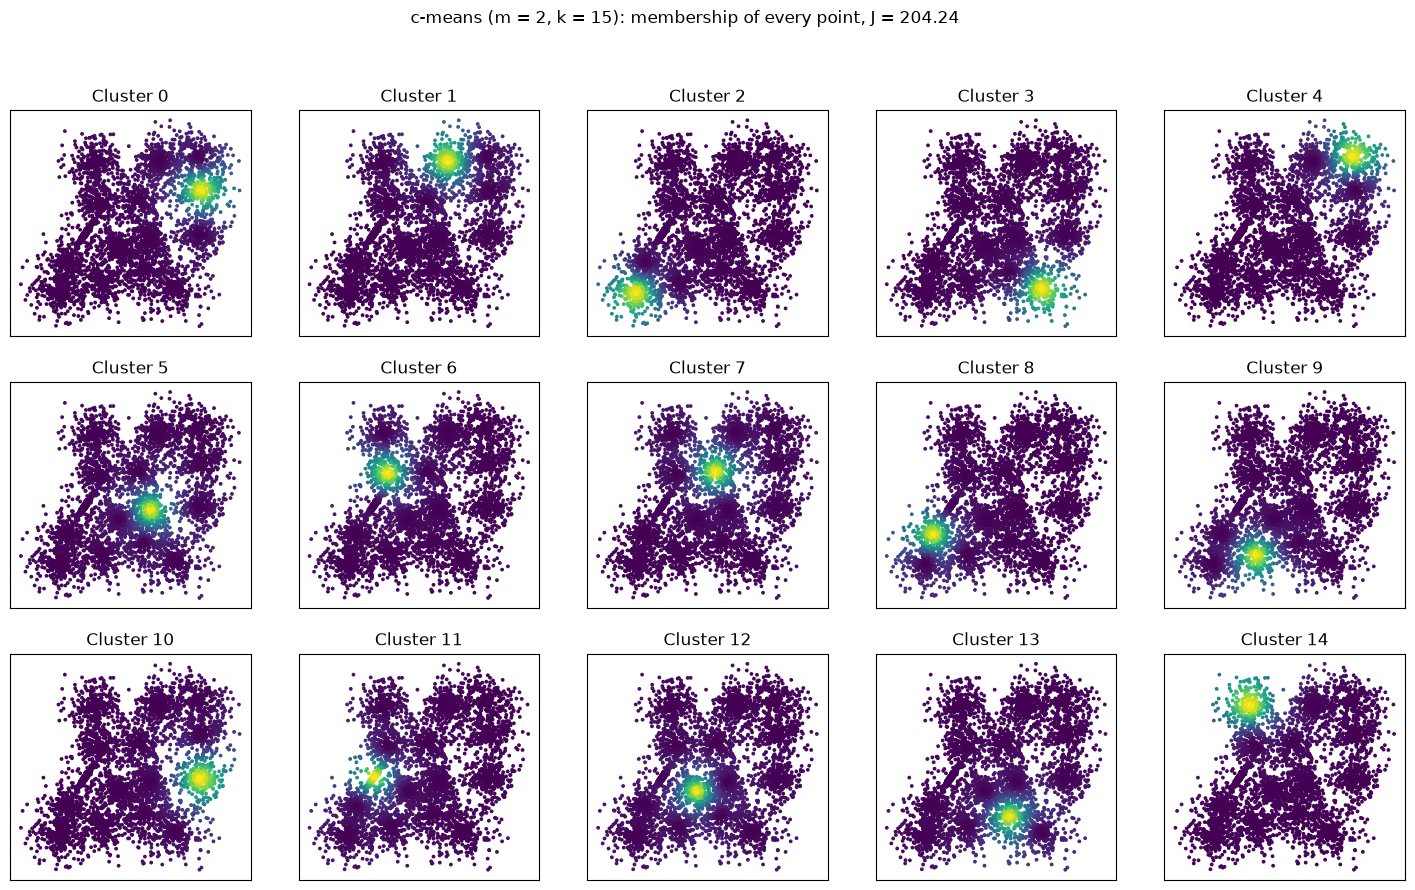

In [41]:
# Memberships of the best c-means with k = 15
runs = [cmeans(s3, 15, rng=np.random.default_rng(i)) for i in range(20)]
U, cen, J, _ = min(runs, key=lambda r: r[2])

fig, axs = plt.subplots(3, 5, figsize=(18, 10))
for j, ax in enumerate(axs.ravel()):
    ax.scatter(s3[:, 0], s3[:, 1], c=U[:, j], cmap="viridis", s=3, vmin=0, vmax=1)
    ax.set_title(f"Cluster {j}"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"c-means (m = 2, k = 15): membership of every point, J = {J:.2f}")
plt.show()

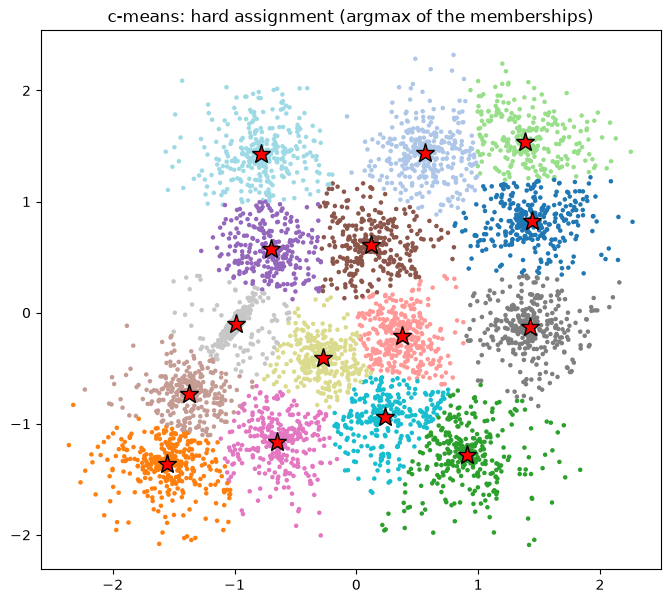

In [42]:
# Hard assignment obtained with the largest membership
plt.figure(figsize=(8, 7))
plt.scatter(s3[:, 0], s3[:, 1], c=U.argmax(axis=1), cmap="tab20", s=5)
plt.plot(cen[:, 0], cen[:, 1], "r*", markersize=14, markeredgecolor="k")
plt.title("c-means: hard assignment (argmax of the memberships)")
plt.show()

**Discussion.** Also the $c$-means scree plot (computed on the fuzzy loss $J_2$) bends around $k=15$, but the elbow is less pronounced than in the hard-clustering cases. In the membership maps every cluster has memberships close to 1 near its center and decreasing smoothly towards the neighbors: points between two overlapping clusters get shared memberships, a piece of information that hard clustering throws away. Hard labels can be recovered with the `argmax` of the memberships. Since $m=2$ spreads the memberships, the value of $J_2$ is not comparable with the $k$-means loss; and the result depends on the fuzzifier $m$ (for $m\to1$ we recover $k$-means, for large $m$ all memberships tend to $1/k$).